# Use viewmastR with large query objects

A query of hundreds of thousands of cells, or millions, does not need to fit in memory. Open it on disk
(`backed="r"`), train the model once, and let `viewmastR_infer()` read and label the query
in row chunks. This tutorial follows the R article
[How to use viewmastR with large query objects](https://furlan-lab.github.io/viewmastR/articles/BigQuery.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query | pediatric leukaemia, ScPCA project [SCPCP000003](https://scpca.alexslemonade.org/projects/SCPCP000003): 511,195 cells from T-ALL, AML and T/myeloid mixed phenotype acute leukaemia samples, raw counts in h5ad (22 GB) |

Download the project as merged AnnData from the ScPCA Portal (free account), then set
`scpca_SCPCP000003` in `data_paths.json`. To label your own large query, open it the same
way: `anndata.read_h5ad(path, backed="r")`.

In [1]:
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

cfg = td.config()
label = cfg.get("greenleaf_label", "celltype")
ref = td.greenleaf_reference()
query = td.large_query()
print(f"query: {query.n_obs:,} cells x {query.n_vars:,} genes, on disk")

query: 511,195 cells x 60,319 genes, on disk


## Train once

Feature selection on the reference keeps the example light; any gene list works. Only
genes present in the query are kept.

In [2]:
vm.calculate_feature_dispersion(ref)
vm.select_features(ref, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
genes = set(query.var_names)
vg = [g for g in vm.get_selected_features(ref) if g in genes]
model_dir = Path(tempfile.mkdtemp()) / "model"
res = vm.viewmastR(None, ref, label, selected_features=vg, max_epochs=4, train_only=True, model_dir=model_dir)
print(f"{len(vg)} features; training took {res.seconds:.0f} s")

viewmastR: 9665 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 90.277% | validation accuracy 96.049%]


[epoch 2 | train accuracy 97.591% | validation accuracy 96.600%]


[epoch 3 | train accuracy 98.675% | validation accuracy 96.751%]


9665 features; training took 12 s


[epoch 4 | train accuracy 99.374% | validation accuracy 96.903%]


## Infer in chunks

`chunk_size` sets how many cells are read and labelled at a time. It bounds memory; it
does not change the result. Two chunk sizes give identical labels.

In [3]:
timing = {}
for col, size in (("test1", 20_000), ("test2", 200_000)):
    t0 = time.time()
    vm.viewmastR_infer(query, model_dir, vg, query_celldata_col=col, chunk_size=size)
    timing[size] = time.time() - t0
    print(f"chunk_size={size:,}: {timing[size]:.0f} s")
same = (query.obs["test1"].astype(str) == query.obs["test2"].astype(str)).all()
print("identical labels:", same)

chunk_size=20,000: 5625 s


chunk_size=200,000: 843 s
identical labels: True


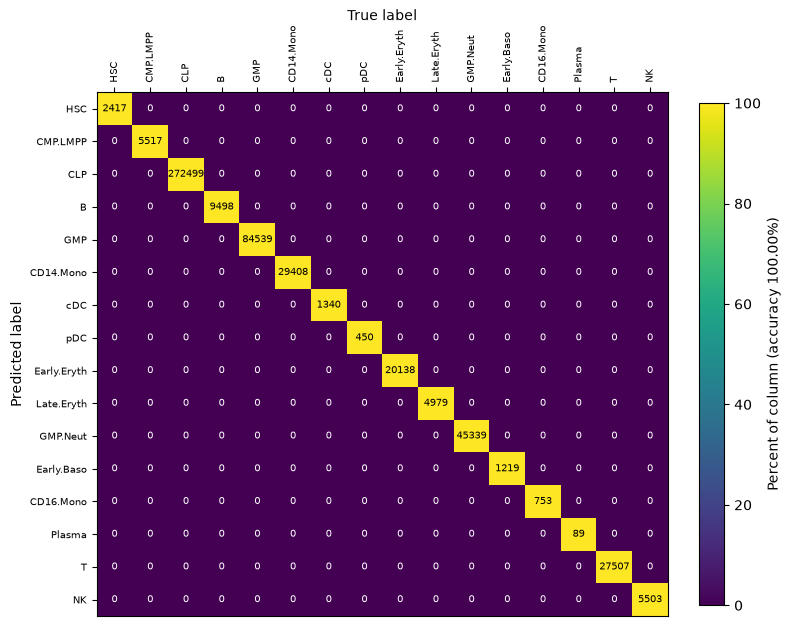

In [4]:
vm.confusion_matrix(query.obs["test1"], query.obs["test2"])
plt.show()

## Predicted composition

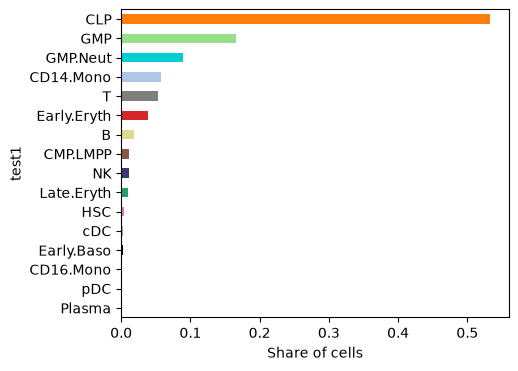

In [5]:
frac = query.obs["test1"].value_counts(normalize=True).sort_values()
frac.plot.barh(figsize=(5, 4), color=[vm.palette.color(t) for t in frac.index])
plt.xlabel("Share of cells")
plt.show()

## Query UMAP

The ScPCA file carries a UMAP of all its cells (`X_umap`). The UMAP needs no counts, so it
is drawn while the counts stay on disk. The cells form many separate islands, and each island
has one diagnosis. The ScPCA UMAP has no batch correction, so the islands mostly follow the
sample. Leukaemic blasts have no healthy counterpart in the reference, so viewmastR gives them
the closest healthy type. Here that is most often CLP, about half of all cells.

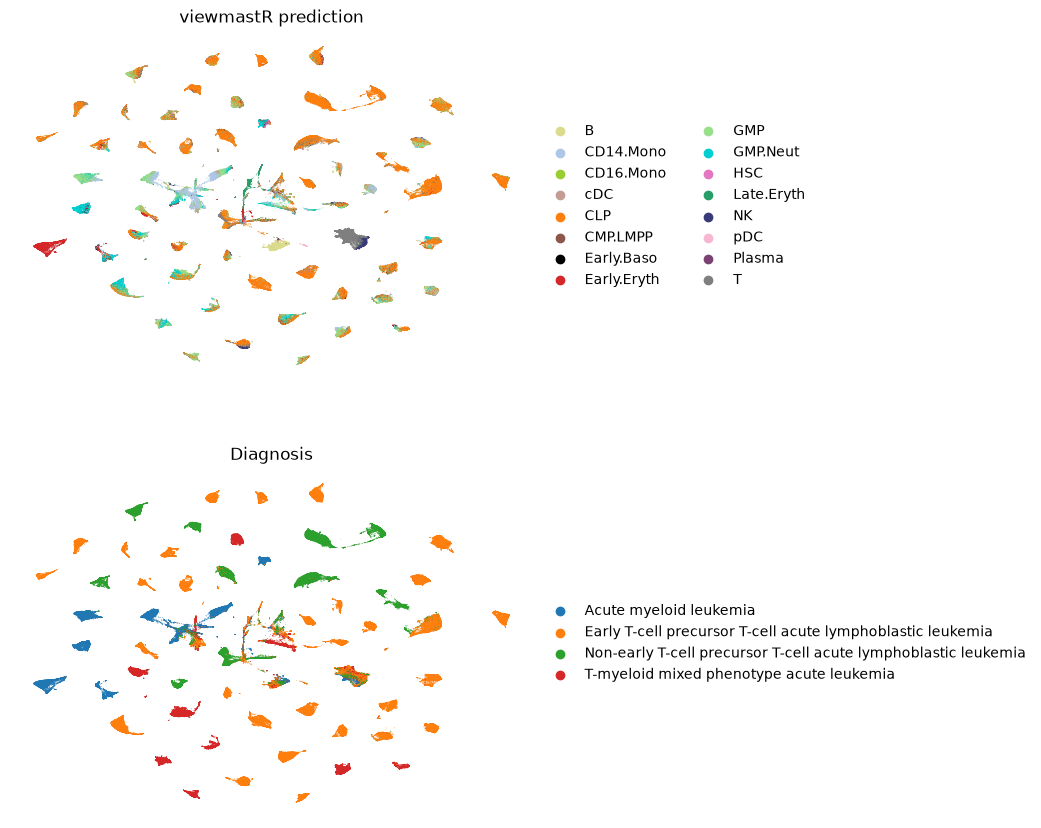

In [6]:
umap = sc.AnnData(obs=query.obs[["test1", "diagnosis"]].copy(), obsm={"X_umap": np.asarray(query.obsm["X_umap"])})
vm.palette.set_colors(umap, "test1")
sc.pl.umap(umap, color=["test1", "diagnosis"], ncols=1, size=1, frameon=False,
           title=["viewmastR prediction", "Diagnosis"])

ScPCA also labels the cells with SingleR against a healthy reference
(`singler_celltype_annotation`), so the two label sets can be compared. Cells that SingleR
did not label show as `nan`.

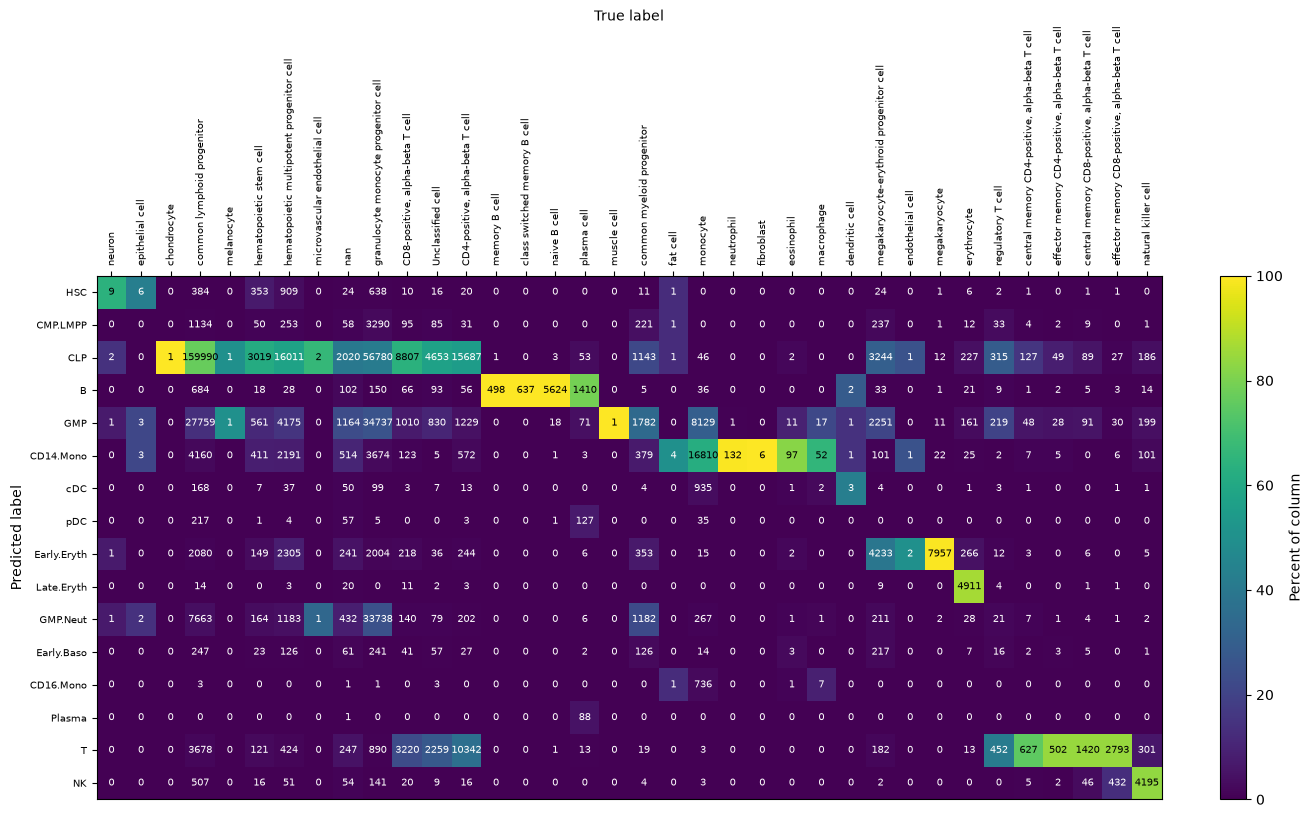

In [7]:
vm.confusion_matrix(query.obs["test1"], query.obs["singler_celltype_annotation"])
plt.show()

## Versions

In [8]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
